# Lab 03: acquire small scientific inputs and explain failures

Automated Workflows in Satellite Image Processing · v1.0 · 15 October 2026

Lab 02 discovered catalogue items and stored one preview. This lab acquires the red
and near-infrared bands needed for NDVI, but stores only a small area of interest.
You design the new database tables completely and then use the resulting archive
to investigate failures.

Use this notebook for predictions, SQL inspection and explanations. Edit
`student_schema.sql` in your editor. Run acquisition and failure cases in a terminal.
The supplied Python is working code, not a new function-repair exercise.

Deliverables: your full schema SQL, your diagnostic SQL, this notebook with evidence
and explanations, and a small final JSON report. Core work: approximately two hours.


## 1. Setup and continuity

Read README.md for installation. From a terminal in this folder, install Rasterio,
NumPy, Matplotlib and Jupyter into your existing environment if needed:

```bash
conda install -c conda-forge "rasterio>=1.4,<2" numpy matplotlib jupyterlab ipykernel
```

We preserve Lab 02's streams, scenes, downloads, runs and stream_scenes tables. You
can copy your database with --from-lab2 on the first init; README.md gives the command.
The default path creates a separate Lab 03 archive and uses captured actual Lab 01
metadata. The original Lab 02 database is never edited by the copy operation.

The fixed example is from June 2025. It is chosen for reproducibility, not presented
as the newest acquisition. Live acquire commands always read remote COG data;
packaged real subsets are used only by offline checks.


In [7]:
from pathlib import Path
import json
import sqlite3
import subprocess
import sys

PROJECT = Path.cwd().resolve()
assert (PROJECT / 'lab03_cli.py').is_file(), 'Set PROJECT to the extracted lab folder'

def run_checks():
    result = subprocess.run([sys.executable, str(PROJECT / 'check_lab03.py')], cwd=PROJECT, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print('Exit code:', result.returncode)
    return result.returncode

print('Project:', PROJECT)

import os
# PostgreSQL/PostGIS points PROJ to its own, older proj.db.
# Removing these for this kernel lets Rasterio use its bundled PROJ data.
for name in ('PROJ_LIB', 'PROJ_DATA'):
    print(name, 'was:', os.environ.pop(name, None))

Project: C:\Users\Karolina\automated_workflows\Automated_Workflows\Labs\Lab03
PROJ_LIB was: C:\Program Files\PostgreSQL\17\share\contrib\postgis-3.5\proj
PROJ_DATA was: None


## 2. Design five complete tables (45–60 minutes)

Read SCHEMA_CONTRACT.md. Write every CREATE TABLE statement yourself in
student_schema.sql. The file initially contains only comments. Required column
names let the supplied service use your schema, but there are no partial table
statements to complete.

Before writing SQL, sketch these relationships and explain the expected cardinality:

| Parent | Child | Question |
|---|---|---|
| scenes | assets | Can one scene have more than one band or metadata revision? |
| assets | subset_requests | Can the same band be stored for two AOIs? |
| subset_requests | download_attempts | Can a request fail and later succeed? |
| runs | download_attempts | Can one invocation attempt more than one band? |
| download_attempts | artifacts | Which attempt first registered these exact bytes? |
| artifacts | artifact_locations | Can a stored file disappear without erasing the artifact's identity? |

Also record each request's latest artifact and each attempt's result artifact.
Those artifacts must belong to the same request, not simply be any existing ID.
The contract explains the composite references needed for that condition.

Which facts belong to current state, and which must remain as history? Do not
make run_id or subset_id unique in the attempts table. Predict what that would
prevent during recovery.


In [10]:
run_checks()


PASS: five complete table definitions and column contract
PASS: primary keys and scene/asset/request/run foreign keys
PASS: AOI identity, uniqueness and allowed states
PASS: attempt outcomes, timestamps and byte counts
PASS: composite relationships prevent cross-AOI artifact references
PASS: real-file verification, missing/corrupt diagnosis and preserved success history
PASS: real B04/B08 grids, AOI masking, scale/offset and pixel cap
PASS: server ignoring Range is refused without reading its body
All checks used actual captured EO data; no live network requests were made.

attempt=attempt-16ca7032-f7dd-4ec7-87fe-257e6c343afa code=FILE_MISSING Recorded file is absent: real_red_aoi.tif
attempt=attempt-d724dd05-8f48-47ca-a3e5-817c8c2c4905 code=FILE_CORRUPT Size/hash mismatch for real_red_aoi.tif

Exit code: 0


0

Write your schema explanation here. Identify two uniqueness constraints and two
foreign key constraints, and give a concrete bad record each would reject. Explain
why an asset+band identity alone is insufficient when the AOI changes.

* UNIQUE (asset_id, aoi_key, recipe_version) in subset_requests ensures one request per band, AOI and recipe; it rejects registering the same red band with the same AOI and recipe a second time. UNIQUE (subset_id, sha256) in artifacts ensures identical bytes of one request are registered once; it rejects a second artifact row with the same request and hash, so a re-download with identical bytes reuses the existing artifact.

* FOREIGN KEY (collection, item_id) in assets rejects an asset for a scene that does not exist in scenes. The composite FOREIGN KEY (latest_artifact_id, subset_id) REFERENCES artifacts (artifact_id, subset_id) rejects a request pointing to an artifact of a different AOI; a single-column key would accept it, because that artifact exists.

* Why asset + band is not enough? The asset already identifies the scene and its date. What it does not identify is the area: the same red band can be cut to two different AOIs, producing different files. With asset + band as the identity, both AOIs would share one request, and acquiring the second would replace the first one’s latest artifact. Including aoi_key and recipe_version gives each AOI its own request.

* run_id and subset_id are not unique in download_attempts, because one run attempts several bands and one request can be retried after a failure; making either unique would make retries impossible.

* 'schema-check' is included in the stage list because the supplied check_lab03.py labels its test attempts with it; all other values follow the contract.


## 3. Plan before storing scientific data (10 minutes)

Once checks pass, initialize the new archive and inspect the planned size:

```bash
python lab03_cli.py init --config config/krakow_aoi.json
```

```bash
python lab03_cli.py plan --config config/krakow_aoi.json
```

Open config/krakow_aoi.json. Distinguish discovery_bbox, which selects catalogue
candidates, from aoi_bbox, which limits the stored pixels. Both use west, south,
east, north in EPSG:4326. item_id pins one tile; the AOI must fit entirely inside it.

For each band, report source_shape, subset shape, pixel size, CRS, raw pixel bytes,
scale and offset. The supplied default should produce 227 rows by 219 columns at
10 m resolution, much smaller than the 10,980 by 10,980 source tile.

Use the alternative too_large_aoi.json configuration to investigate a budget failure:

```bash
python lab03_cli.py plan --config config/too_large_aoi.json
```

That command is expected to fail before remote raster data is read. Explain why a
local disk limit and an HTTP transfer limit are different controls. Reading a COG
window fetches whole source blocks; network bytes may exceed stored file bytes.

* The local disk limit controls how many bytes may be stored in the output files, while the HTTP limit controls how many bytes may be received over the network during a transfer. The two can differ a lot: a COG is stored in compressed internal blocks, and every block the AOI touches must be downloaded completely (plus the file header), even if only a few of its pixels are kept. The AOI is cut out and recompressed only after the download, so the network bytes depend on the remote file’s block layout, while the stored bytes depend on the size of the crop, which is why each needs its own limit


## 4. Acquire and repeat (10 minutes plus network time)

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py report --config config/krakow_aoi.json
```

The first run requests two real bands via byte ranges and stores two masked AOI
GeoTIFFs. The second checks their size, SHA-256 and raster metadata and records
reused attempts. Explain why reused is not another transfer and why it is still
worth recording.

* A reused attempt is not another transfer as no HTTP request is sent (http_status is null and network_bytes is 0). The service verifies the existing local file against its artifact record: size, SHA-256 hash and raster metadata. It is still worth recording because it is evidence that, at that moment, the file existed and matched the recorded bytes, so this run delivered verified inputs. Without the row, a run that verified its files would be indistinguishable from one that checked nothing, and if a later check finds the file missing or corrupt, the history shows when it was last confirmed intact.

Open state/catalogue.sqlite in DB Browser. Inspect the five original tables and
your five new tables. Existing preview downloads remain in downloads; scientific
cutout attempts are in download_attempts and link to subset_requests.


### One worked SQL join

Run this in Execute SQL. It follows an attempt to its run, AOI request and source
band. Use it as a starting point for your own diagnostic queries.

```sql
SELECT r.run_id, r.command, a.item_id, a.asset_key,
       s.aoi_key, d.status, d.stage, d.network_bytes,
       d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;
```

Write your own query to show the saved paths, file hashes and latest location
states. Compare HTTP bytes with file sizes. Do not sum bytes after joining a
one-to-many location table unless you account for the duplicated attempt rows.


In [11]:
def query(sql, db=None):
    db = db or (PROJECT / 'state' / 'catalogue.sqlite')
    with sqlite3.connect(f'{db.as_uri()}?mode=ro', uri=True) as conn:
        conn.row_factory = sqlite3.Row
        rows = [dict(r) for r in conn.execute(sql)]
    for r in rows:
        print(r)
    return rows

In [16]:
query('''
SELECT r.run_id, r.command, a.item_id, a.asset_key,
       s.aoi_key, d.status, d.stage, d.network_bytes,
       d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id
''');

{'run_id': 'lab03-378deb92-87c4-4a60-bfbf-b6647b9c4af6', 'command': 'acquire', 'item_id': 'S2C_34UDA_20250605_0_L2A', 'asset_key': 'red', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'http_status': 206, 'error_code': None, 'error_message': None}
{'run_id': 'lab03-378deb92-87c4-4a60-bfbf-b6647b9c4af6', 'command': 'acquire', 'item_id': 'S2C_34UDA_20250605_0_L2A', 'asset_key': 'nir', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'http_status': 206, 'error_code': None, 'error_message': None}
{'run_id': 'lab03-b086bb04-2d05-4f3e-b58a-5e0e85c531c7', 'command': 'acquire', 'item_id': 'S2C_34UDA_20250605_0_L2A', 'asset_key': 'red', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'status': 'reused', 'stage': 'cache_verify', 'network_bytes': 0, 'http_status': Non

In [17]:
query("""
SELECT a.asset_key, l.local_path, f.sha256,f.size_bytes AS saved_bytes, d.network_bytes AS http_bytes,l.status AS location_status,l.checked_at
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
JOIN download_attempts AS d ON d.attempt_id  = f.created_by_attempt_id
ORDER BY a.asset_key
""");

{'asset_key': 'nir', 'local_path': 'C:\\Users\\Karolina\\automated_workflows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\nir-dcfea4a7d5a3e6ef.tif', 'sha256': 'b8cf04708203ae6ee6a7306f4232b7a69370a397a14a05da1dd41bdb45bf0e49', 'saved_bytes': 75702, 'http_bytes': 2097153, 'location_status': 'available', 'checked_at': '2026-11-13T15:37:08.851446Z'}
{'asset_key': 'red', 'local_path': 'C:\\Users\\Karolina\\automated_workflows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\red-59c9437e300a3549.tif', 'sha256': '8363a5d2259d08d542985156aae667a6d37211dad1900f8c836c93f055c60a2a', 'saved_bytes': 75490, 'http_bytes': 2097153, 'location_status': 'available', 'checked_at': '2026-11-13T15:37:08.841989Z'}


In [18]:
DB = PROJECT / 'state' / 'catalogue.sqlite'
if not DB.is_file():
    print('Write/check the schema and run init/acquire in the terminal first.')
else:
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'download_attempts' not in names:
            print('The five new tables have not been initialized yet.')
        else:
            conn.row_factory = sqlite3.Row
            rows = [dict(row) for row in conn.execute('SELECT run_id,status,stage,network_bytes,error_code FROM download_attempts ORDER BY rowid')]
            print(json.dumps(rows, indent=2))


[
  {
    "run_id": "lab03-378deb92-87c4-4a60-bfbf-b6647b9c4af6",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-378deb92-87c4-4a60-bfbf-b6647b9c4af6",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-b086bb04-2d05-4f3e-b58a-5e0e85c531c7",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-b086bb04-2d05-4f3e-b58a-5e0e85c531c7",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  }
]


## 5. Failure case A: one band succeeded, then the connection failed (20 minutes)

Predict the database and file states before running this:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name network
```

The command creates cases/network/config.json and its own database/data directory,
then deliberately interrupts the nir reader after actual range responses. A
failure exit code is expected. It does not damage the main archive. The connection
failure is controlled; the scene records and imagery are real.

Open cases/network/state/catalogue.sqlite. Before any recovery:

1. Write SQL to identify the failed run, failed band, failure stage and bytes received.
2. Show which band already has an artifact and which has none.
3. Explain why a failed run does not imply that every operation in it failed. How could an INNER JOIN to artifacts hide the failed attempt?
4. Explain why advancing a discovery watermark would not prove a band was stored.

Record evidence, then recover:

```bash
python lab03_cli.py acquire --config cases/network/config.json
```

Show that the red file was verified/reused, the nir operation was retried, and the
original failure remains in the attempts table. Do not overwrite the failed row
to make the history look successful. Finish with a small before/after table of
run, band, attempt status, stage and artifact identity.

1. query 1: Run lab03-8603de23… failed. Inside it, red succeeded (2,097,153 bytes, HTTP 206), while nir failed at stage read_window with RANGE_READ_FAILED after receiving 262,145 bytes.

2. query 2: Red is ready with artifact 59c9437e… and an available file of 75,490 bytes. Nir is failed, with no artifact and no location.

3. A failed run is not a failure of every operation. The run status summarizes the whole command: it fails if any band fails. The attempts inside it have their own outcomes, and red’s success is real and kept. An INNER JOIN to artifacts keeps only requests that have an artifact, so the failed nir request disappears from the result (query 3), and the output looks as if everything was fine. A LEFT JOIN keeps every request and shows the missing artifact as NULL.

4. A discovery watermark does not prove a band was stored. The watermark only records how far the catalogue search was completed, i.e. which scene metadata was found. Downloading bands is a separate step with its own records. Only an artifact with an available, verified location proves that a band was stored.


In [31]:
DB_A = PROJECT / 'cases' / 'network' / 'state' / 'catalogue.sqlite'

query('''
SELECT r.status AS run_status, a.asset_key, d.status, d.stage, d.network_bytes, d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at
''', DB_A);
print("---")
query('''
SELECT a.asset_key, s.status AS request_status, s.latest_artifact_id, f.size_bytes, l.status AS location_status
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key
''', DB_A);
print("---")
query('''
SELECT a.asset_key, s.status AS request_status, s.latest_artifact_id
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
''', DB_A);

{'run_status': 'failed', 'asset_key': 'red', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'http_status': 206, 'error_code': None, 'error_message': None}
{'run_status': 'failed', 'asset_key': 'nir', 'status': 'failed', 'stage': 'read_window', 'network_bytes': 262145, 'http_status': 206, 'error_code': 'RANGE_READ_FAILED', 'error_message': 'Controlled network interruption after actual range responses'}
{'run_status': 'succeeded', 'asset_key': 'red', 'status': 'reused', 'stage': 'cache_verify', 'network_bytes': 0, 'http_status': None, 'error_code': None, 'error_message': None}
{'run_status': 'succeeded', 'asset_key': 'nir', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'http_status': 206, 'error_code': None, 'error_message': None}
{'run_status': 'succeeded', 'asset_key': 'red', 'status': 'reused', 'stage': 'cache_verify', 'network_bytes': 0, 'http_status': None, 'error_code': None, 'error_message': None}
{'run_status': 'succeeded', 'asset_ke

The failed result:
``` bash
{'run_status': 'failed', 'asset_key': 'red', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'http_status': 206, 'error_code': None, 'error_message': None}
{'run_status': 'failed', 'asset_key': 'nir', 'status': 'failed', 'stage': 'read_window', 'network_bytes': 262145, 'http_status': 206, 'error_code': 'RANGE_READ_FAILED', 'error_message': 'Controlled network interruption after actual range responses'}
---
{'asset_key': 'nir', 'request_status': 'failed', 'latest_artifact_id': None, 'size_bytes': None, 'location_status': None}
{'asset_key': 'red', 'request_status': 'ready', 'latest_artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db', 'size_bytes': 75490, 'location_status': 'available'}
---
{'asset_key': 'red', 'request_status': 'ready', 'latest_artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db'}
```

After recovery, red was verified and reused (0 network bytes, same artifact), and nir was retried and succeeded, producing artifact. The original nir failure remains in download_attempts with its stage, error code and byte count; the recovery added new attempt rows instead of overwriting it. The first run stays marked as failed, because at that time it really did fail. Both nir artifact IDs here and in the main archive are identical, because the same AOI of the same band produced the same bytes.

## 6. Failure case B: recorded success, missing file (20 minutes)

Predict whether a foreign key can detect a missing disk file. Then run:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name missing
```

This creates an independent case, acquires real subsets, deletes only that case's
red file, and verifies the archive. A failure exit code is expected. Inspect
cases/missing/state/catalogue.sqlite before recovery.

Write diagnostic SQL and explain:

- Which historical attempt succeeded? Which later operation detected the loss?
 * The red attempt attempt-d9e7b533… in the acquire run succeeded (2,097,153 network bytes, artifact). The later verify run’s red attempt failed at cache_verify with FILE_MISSING, still pointing to the same artifact.
- Which table describes the file's current availability, and which describes the
  bytes that previously existed?
  * artifact_locations describes the current availability: the red location is now missing, with the time of the check. artifacts describes the bytes that previously existed: hash, size and the attempt that created them.
- Why should the original successful attempt remain successful in the history?
  * Because it describes what happened at that time: the download really did succeed, and the file was valid. The loss is a separate, later event, recorded as its own failed attempt. Overwriting the success would erase the evidence that good bytes once existed, and hide when the problem appeared.
- What can the database prove, and what required reading the filesystem?
  * The database proves the records and their relationships: the artifact exists, belongs to this request, and was created by that attempt. A foreign key only checks rows in tables, so it cannot detect a missing file; the constraints were all still satisfied after the deletion. Detecting the loss required reading the filesystem: checking that the file exists, and comparing its size and SHA-256 hash.

Recover with the same configuration:

```bash
python lab03_cli.py acquire --config cases/missing/config.json
```

Confirm red was restored and nir was reused. If the restored GeoTIFF has the same
hash, explain why it may retain the same artifact identity while having a new
successful transfer attempt.

Optional: --name corrupt truncates a real case file instead of deleting it.
Compare FILE_CORRUPT with FILE_MISSING. --name interrupted stops after writing a
valid temporary cutout but before finalization; explain why no successful artifact
should be registered for that attempt. Generate each case once; later use its
existing configuration to inspect or recover it.


In [32]:
DB_B = PROJECT / 'cases' / 'missing' / 'state' / 'catalogue.sqlite'

query('''
SELECT r.command, r.status AS run_status, a.asset_key, d.status, d.stage,
       d.network_bytes, d.error_code, d.artifact_id
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at
''', DB_B);
print("---")
query('''
SELECT a.asset_key, s.status AS request_status, f.artifact_id,
       f.created_by_attempt_id, l.local_path, l.status AS location_status, l.checked_at
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key
''', DB_B);
print("---")


{'command': 'acquire', 'run_status': 'succeeded', 'asset_key': 'red', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'error_code': None, 'artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db'}
{'command': 'acquire', 'run_status': 'succeeded', 'asset_key': 'nir', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'error_code': None, 'artifact_id': 'dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e'}
{'command': 'verify', 'run_status': 'failed', 'asset_key': 'red', 'status': 'failed', 'stage': 'cache_verify', 'network_bytes': 0, 'error_code': 'FILE_MISSING', 'artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db'}
{'command': 'verify', 'run_status': 'failed', 'asset_key': 'nir', 'status': 'reused', 'stage': 'cache_verify', 'network_bytes': 0, 'error_code': None, 'artifact_id': 'dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e'}
---
{'asset_key': 'nir', 'request_st

In [33]:
# AFTER THE RESTORATION
DB_B = PROJECT / 'cases' / 'missing' / 'state' / 'catalogue.sqlite'

query('''
SELECT r.command, r.status AS run_status, a.asset_key, d.status, d.stage,
       d.network_bytes, d.error_code, d.artifact_id
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at
''', DB_B);
print("---")
query('''
SELECT a.asset_key, s.status AS request_status, f.artifact_id,
       f.created_by_attempt_id, l.local_path, l.status AS location_status, l.checked_at
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key
''', DB_B);
print("---")


{'command': 'acquire', 'run_status': 'succeeded', 'asset_key': 'red', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'error_code': None, 'artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db'}
{'command': 'acquire', 'run_status': 'succeeded', 'asset_key': 'nir', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'error_code': None, 'artifact_id': 'dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e'}
{'command': 'verify', 'run_status': 'failed', 'asset_key': 'red', 'status': 'failed', 'stage': 'cache_verify', 'network_bytes': 0, 'error_code': 'FILE_MISSING', 'artifact_id': '59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db'}
{'command': 'verify', 'run_status': 'failed', 'asset_key': 'nir', 'status': 'reused', 'stage': 'cache_verify', 'network_bytes': 0, 'error_code': None, 'artifact_id': 'dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e'}
{'command': 'acquire', 'run_status':

After recovery, red was downloaded again in a new successful attempt (2097153 network bytes), and nir was reused. The restored red GeoTIFF has the same SHA-256 hash as before, so it keeps the same artifact identity, and the artifact still records the original attempt as its creator. The recovery appears as a new attempt, and the location changes from missing back to available. The full history keeps the original success, the failed verification and the failed cache check before the new download.

## 7. A new AOI is a different request (10 minutes)

Compare the plan for a smaller AOI of the same scene:

```bash
python lab03_cli.py plan --config config/alternate_aoi.json
```

Optional small acquisition:

```bash
python lab03_cli.py acquire --config config/alternate_aoi.json
```

Write SQL showing that the same source asset can have two subset requests and
that each request points to the correct output. 

- Why would UNIQUE(asset_id) on subset_requests break this?
  * It would allow only one request per source band. The small AOI’s request for the red band would be rejected (the service uses INSERT OR IGNORE, so it would be silently skipped), and its attempts would then fail because their request does not exist. Different AOIs of the same band could never coexist, although they are different crops with different files.
- Why would two independent foreign keys fail to prove that an artifact belongs to the right request?
  * A single-column key on latest_artifact_id only checks that the artifact exists. The large AOI’s red request could then point to the small AOI’s artifact: it exists, so the key would accept it, although it is the wrong file. The composite key (latest_artifact_id, subset_id) → artifacts (artifact_id, subset_id) checks that the artifact exists with this same request, so the mix-up is rejected.


In [34]:
query('''
SELECT a.asset_key, a.asset_id, s.subset_id, s.aoi_json,
       s.status, s.latest_artifact_id, l.local_path
FROM assets AS a
JOIN subset_requests AS s ON s.asset_id = a.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key, s.aoi_json
''', DB);

{'asset_key': 'nir', 'asset_id': 'a2d220b3d0db776bd878281b88dd3d085be4ddc78042674be044110f202bdff8', 'subset_id': 'f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e', 'aoi_json': '{"bbox":[19.91,50.04,19.94,50.06],"crs":"EPSG:4326"}', 'status': 'ready', 'latest_artifact_id': 'dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e', 'local_path': 'C:\\Users\\Karolina\\automated_workflows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\nir-dcfea4a7d5a3e6ef.tif'}
{'asset_key': 'nir', 'asset_id': 'a2d220b3d0db776bd878281b88dd3d085be4ddc78042674be044110f202bdff8', 'subset_id': '9d71da0367a3fae0f0f93671894a6c003c4ad3bb3c64b810f29e5e64c56efa49', 'aoi_json': '{"bbox":[19.92,50.045,19.935,50.055],"crs":"EPSG:4326"}', 'status': 'ready', 'latest_artifact_id': 'b988851930323e6e60a58d9a2f723333a36be41458157a81b8def7d5da5dbde8', 'local_path': 'C:\\Users\\Karolina\\automated_workflows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605

## 8. Optional inspection: prepare for NDVI processing

B04/red and B08/nir are the two 10 m inputs for this exercise. Inspect their
reflectance, not unsigned integer arithmetic. Rasterio does not automatically
apply the stored scale and offset when read() returns an array. The offset can
change NDVI; assuming all calibration factors cancel is unsafe.

The cell below reads your main archive only. It does not download anything or
register a derived product. NDVI is shown for inspection; cloud masking, formal
QC and product registration belong to later work.


red (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1
nir (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1


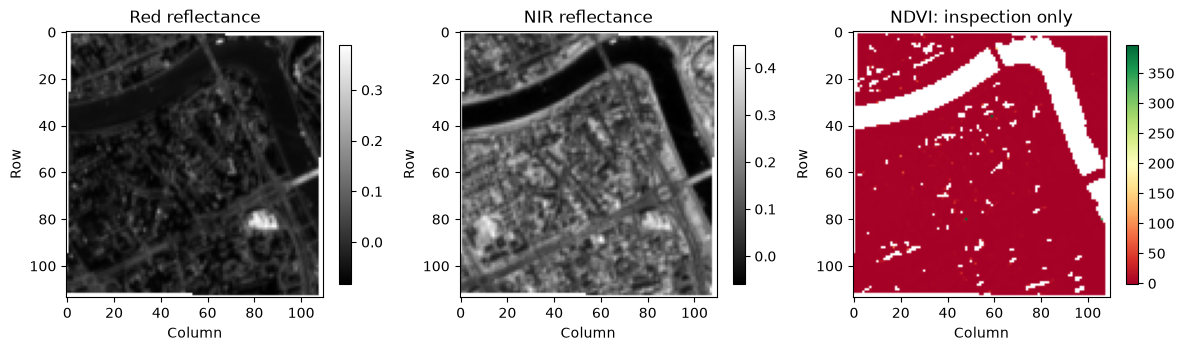

In [36]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

paths = {}
if DB.is_file():
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'artifact_locations' in names:
            for band, path in conn.execute("""SELECT a.asset_key,l.local_path FROM subset_requests s
                JOIN assets a USING(asset_id) JOIN artifact_locations l ON l.artifact_id=s.latest_artifact_id
                WHERE l.status='available' ORDER BY s.updated_at"""):
                paths[band] = Path(path)
if set(paths) != {'red','nir'} or not all(p.is_file() for p in paths.values()):
    print('Acquire both main-archive AOI subsets first; no download is performed by this cell.')
else:
    arrays = {}
    grids = {}
    for band, path in paths.items():
        with rasterio.open(path) as src:
            grids[band] = (src.crs, src.transform, src.shape)
            arrays[band] = src.read(1, masked=True).astype('float32') * src.scales[0] + src.offsets[0]
            print(band, src.shape, src.crs, 'scale:', src.scales[0], 'offset:', src.offsets[0])
    assert grids['red'] == grids['nir'], 'Choose the same AOI and aligned bands'
    red, nir = arrays['red'], arrays['nir']
    denominator = nir + red
    with np.errstate(divide='ignore', invalid='ignore'):
        ndvi = np.ma.masked_where(denominator <= 0, (nir-red) / denominator)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, values, title in zip(axes,[red,nir,ndvi],['Red reflectance','NIR reflectance','NDVI: inspection only']):
        im = ax.imshow(values, cmap='RdYlGn' if title.startswith('NDVI') else 'gray')
        ax.set_title(title); ax.set_xlabel('Column'); ax.set_ylabel('Row')
        fig.colorbar(im,ax=ax,shrink=0.65)
    plt.tight_layout()
    plt.show()
# it shows the exact same error as we had seen on lab 04 onsite

## Submission and interpretation

Submit student_schema.sql, your investigation_queries.sql, this notebook with
predictions/SQL results/explanations, and a small report:

```bash
python lab03_cli.py report --config config/krakow_aoi.json > lab03_report.json
```

For each required failure, state: symptom, query, observed rows, diagnosis, recovery,
and post-recovery evidence. A screenshot alone is not a diagnosis. Explain which
claims are protected by database constraints and which require checking bytes,
filesystem state or raster metadata.

Keep state/, data/, and cases/ out of Git. Successful offline checks do not claim
that a live request succeeded. If the provider/network is unavailable, retain that
failure evidence and complete the live acquisition later; no synthetic image is
substituted.

Sources: [Rasterio windowed reading/writing](https://rasterio.readthedocs.io/en/latest/topics/windowed-rw.html)
and [Earth Search metadata](https://github.com/Element84/earth-search/blob/main/README.md).
